In [1]:
# importing the required libaries
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 

#### Load and inscpet the datset


In [2]:
# read the csv file
df=pd.read_csv("Coffee Shop Sales - pandas practice .csv")

In [3]:
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,76518.0,2023-04-26,08:41:05,1.0,3.0,Astoria,74.0,3.50,Bakery,Biscotti,NaN
1,114187.0,2023-06-01,09:57:45,2.0,8.0,Hell's Kitchen,33.0,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
2,148133.0,2023-06-29,16:54:00,2.0,3.0,Astoria,61.0,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
3,147662.0,2023-06-29,11:24:00,2.0,3.0,Astoria,58.0,3.50,Drinking Chocolate,Hot chocolate,Dark chocolate Rg
4,53732.0,2023-03-29,19:20:12,2.0,8.0,Hell's Kitchen,24.0,3.00,Coffee,Drip coffee,Our Old Time Diner Blend Lg


In [4]:
df.tail()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
149611,36108.0,2023-03-04,14:36:34,1.0,8.0,Hell's Kitchen,31.0,2.20,Coffee,Gourmet brewed coffee,Ethiopia Sm
149612,83655.0,2023-05-04,09:16:58,1.0,5.0,Lower Manhattan,44.0,2.50,Tea,Brewed herbal tea,Peppermint Rg
149613,NaN,2023-02-19,10:34:03,1.0,3.0,Astoria,58.0,3.50,Drinking Chocolate,Hot chocolate,Dark chocolate Rg
149614,30542.0,2023-02-23,12:00:58,1.0,3.0,Astoria,79.0,3.75,Bakery,Scone,Jumbo Savory Scone
149615,71502.0,2023-04-20,09:12:00,2.0,8.0,Hell's Kitchen,59.0,4.50,Drinking Chocolate,Hot chocolate,NaN


In [5]:
df.shape

(149616, 11)

In [6]:
df.describe()

,transaction_id,store_id,product_id,unit_price
count,148125.000000,148125.000000,148125.000000,148125.000000
mean,74745.596793,5.342103,47.922160,3.381625
std,43156.718723,2.074463,17.929076,2.654729
min,1.000000,3.000000,1.000000,0.800000
25%,37341.000000,3.000000,33.000000,2.500000
50%,74734.000000,5.000000,47.000000,3.000000
75%,112111.000000,8.000000,60.000000,3.750000
max,149456.000000,8.000000,87.000000,45.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149616 entries, 0 to 149615
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    148125 non-null  float64
 1   transaction_date  148125 non-null  object 
 2   transaction_time  148125 non-null  object 
 3   transaction_qty   148125 non-null  object 
 4   store_id          148125 non-null  float64
 5   store_location    148125 non-null  object 
 6   product_id        148125 non-null  float64
 7   unit_price        148125 non-null  float64
 8   product_category  148125 non-null  object 
 9   product_type      148125 non-null  object 
 10  product_detail    148125 non-null  object 
dtypes: float64(4), object(7)
memory usage: 12.6+ MB


#### Data Quality check 

In [8]:
# checking null values
df.isnull().sum()

transaction_id      1491
transaction_date    1491
transaction_time    1491
transaction_qty     1491
store_id            1491
store_location      1491
product_id          1491
unit_price          1491
product_category    1491
product_type        1491
product_detail      1491
dtype: int64

In [9]:
# checking duplicated values
df.duplicated().sum()

np.int64(500)

In [10]:
# checking the data type 
df.dtypes

transaction_id      float64
transaction_date     object
transaction_time     object
transaction_qty      object
store_id            float64
store_location       object
product_id          float64
unit_price          float64
product_category     object
product_type         object
product_detail       object
dtype: object

In [11]:
# checking the unquie values
df.nunique()

transaction_id      147625
transaction_date       181
transaction_time     25755
transaction_qty          9
store_id                 3
store_location           3
product_id              80
unit_price              41
product_category         9
product_type            29
product_detail          80
dtype: int64

#### Data cleaning

In [12]:
# changing the date column into datetime datatype
df["transaction_date"]=df["transaction_date"].astype('<M8[ns]')# m8[ns] is the code of datetime nanoseconds
df['transaction_date'].dtype

dtype('<M8[ns]')

In [13]:
# changing the time to the time datetype
df['transaction_time']=pd.to_datetime(df['transaction_time'],format='%H:%M:%S').dt.time
df['transaction_time'].dtype
df['transaction_time']

0         08:41:05
1         09:57:45
2         16:54:00
3         11:24:00
4         19:20:12
            ...   
149611    14:36:34
149612    09:16:58
149613    10:34:03
149614    12:00:58
149615    09:12:00
Name: transaction_time, Length: 149616, dtype: object

In [14]:
# change the str into float value 
df['transaction_qty']=pd.to_numeric(df["transaction_qty"],errors="coerce")# coerce means it it run also when it has NAn Na value

In [15]:
df["store_location"]=df["store_location"].astype('str')
df["product_category"]=df["product_category"].astype('str')
df["product_type"]=df["product_type"].astype('str')
df["product_detail"]=df["product_detail"].astype('str')


In [16]:
df.dtypes

transaction_id             float64
transaction_date    datetime64[ns]
transaction_time            object
transaction_qty            float64
store_id                   float64
store_location              object
product_id                 float64
unit_price                 float64
product_category            object
product_type                object
product_detail              object
dtype: object

In [17]:
df.drop_duplicates()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,76518.0,2023-04-26,08:41:05,1.0,3.0,Astoria,74.0,3.50,Bakery,Biscotti,nan
1,114187.0,2023-06-01,09:57:45,2.0,8.0,Hell's Kitchen,33.0,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
2,148133.0,2023-06-29,16:54:00,2.0,3.0,Astoria,61.0,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
3,147662.0,2023-06-29,11:24:00,2.0,3.0,Astoria,58.0,3.50,Drinking Chocolate,Hot chocolate,Dark chocolate Rg
4,53732.0,2023-03-29,19:20:12,2.0,8.0,Hell's Kitchen,24.0,3.00,Coffee,Drip coffee,Our Old Time Diner Blend Lg
...,...,...,...,...,...,...,...,...,...,...,...
149611,36108.0,2023-03-04,14:36:34,1.0,8.0,Hell's Kitchen,31.0,2.20,Coffee,Gourmet brewed coffee,Ethiopia Sm
149612,83655.0,2023-05-04,09:16:58,1.0,5.0,Lower Manhattan,44.0,2.50,Tea,Brewed herbal tea,Peppermint Rg
149613,NaN,2023-02-19,10:34:03,1.0,3.0,Astoria,58.0,3.50,Drinking Chocolate,Hot chocolate,Dark chocolate Rg
149614,30542.0,2023-02-23,12:00:58,1.0,3.0,Astoria,79.0,3.75,Bakery,Scone,Jumbo Savory Scone


In [18]:
df.dropna(inplace=True)

#### feature extraction



In [19]:
df["month"]=df["transaction_date"].dt.month
df["year"]=df["transaction_date"].dt.year
df["date"]=df["transaction_date"].dt.day


In [20]:
# creating revenue column
df["revenue"]=df["transaction_qty"]*df["unit_price"]

In [21]:
for i in df.columns[[11,12,13]]:
    df[i]=pd.to_numeric(df[i])

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 139339 entries, 0 to 149615
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    139339 non-null  float64       
 1   transaction_date  139339 non-null  datetime64[ns]
 2   transaction_time  139339 non-null  object        
 3   transaction_qty   139339 non-null  float64       
 4   store_id          139339 non-null  float64       
 5   store_location    139339 non-null  object        
 6   product_id        139339 non-null  float64       
 7   unit_price        139339 non-null  float64       
 8   product_category  139339 non-null  object        
 9   product_type      139339 non-null  object        
 10  product_detail    139339 non-null  object        
 11  month             139339 non-null  int32         
 12  year              139339 non-null  int32         
 13  date              139339 non-null  int32         
 14  revenue  

#### pandas analysis

1) which product sells the most?

In [22]:
df['product_category'].value_counts()

product_category
Coffee                54038
Tea                   42051
Bakery                21112
Drinking Chocolate    10634
Flavours               6261
Coffee beans           1610
nan                    1383
Loose Tea              1129
Branded                 687
Packaged Chocolate      434
Name: count, dtype: int64

2. which product generate the most revenue?


In [23]:
revenue_by_cat=df.groupby('product_category')['revenue'].sum()
print(revenue_by_cat.idxmax(),":",revenue_by_cat.max())

Coffee : 250101.55


3. whivh store have the highest sales?

In [24]:
high_sales_store=df.groupby('store_location')['revenue'].sum()
print(high_sales_store.idxmax(),":",high_sales_store.max())

Hell's Kitchen : 219346.51


4. What are the total quantity sold, average unit price, and number of transactions?

In [25]:
df.groupby("transaction_qty").agg({
    "revenue":"sum",
    "unit_price":"mean",
    "transaction_id":"count"
    })
# it is increasing

,revenue,unit_price,transaction_id
transaction_qty,,,
1.0,300737.18,3.695831,81372
2.0,321238.70,2.928552,54846
3.0,27163.05,2.933058,3087
4.0,200.40,2.385714,21
6.0,216.00,12.000000,3
8.0,3600.00,45.000000,10


5. For each product_category, calculate total quantity sold and total revenue.

In [26]:
df.groupby('product_category')[['transaction_qty','revenue']].sum()


,transaction_qty,revenue
product_category,,
Bakery,21494.0,76248.02
Branded,716.0,12470.00
Coffee,82672.0,250101.55
Coffee beans,1685.0,36991.35
Drinking Chocolate,16183.0,67100.00
Flavours,9683.0,7746.40
Loose Tea,1129.0,10465.00
Packaged Chocolate,434.0,3920.63
Tea,64533.0,181725.85


6. Which date had the most transactions, and how many transactions occurred that day?

In [27]:
high_transcation=df.groupby('date')['transaction_id'].count()
print(high_transcation.idxmax(),":",high_transcation.max())

16 : 5169


### visualization


#### matplotlib charts

<Axes: xlabel='product_category'>

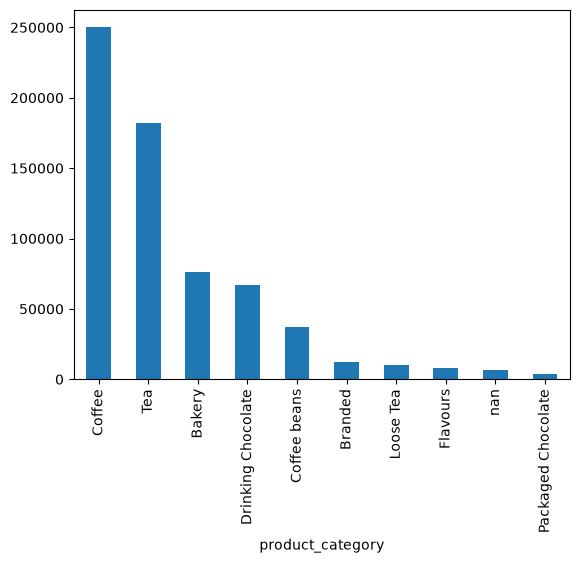

In [28]:
df.groupby('product_category')["revenue"].sum().sort_values(ascending=False).plot.bar()

<Axes: xlabel='days', ylabel='total revenue'>

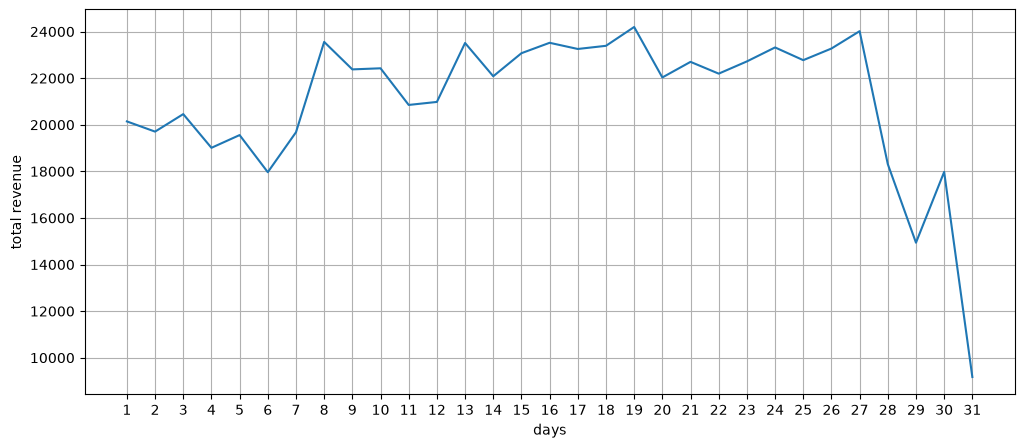

In [29]:
plt.figure(figsize=(12,5))
df.groupby("date")["revenue"].sum().plot(
    xticks=range(1,32,1),
    xlabel="days",
    ylabel="total revenue",
    grid=True)


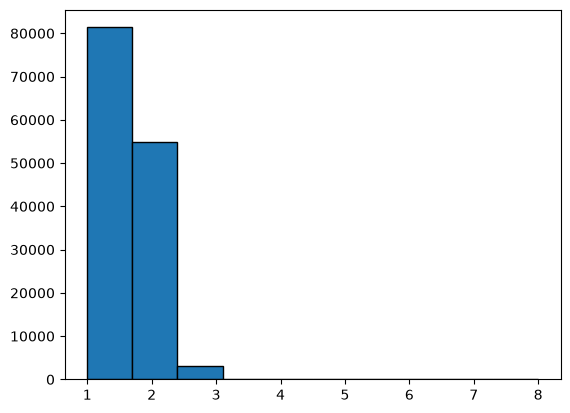

most frequent quanity: 1.0


In [47]:
plt.hist(df["transaction_qty"],edgecolor="black")
plt.show()
print("most frequent quanity:",df["transaction_qty"].mode()[0])

### seaborn ploting

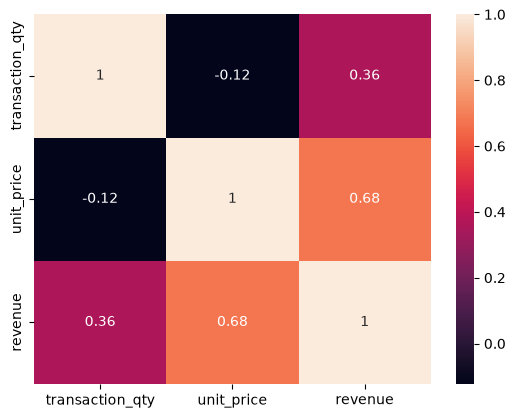

In [48]:
sns.heatmap(
    df[["transaction_qty", "unit_price", "revenue"]].corr(),
    annot=True
)
plt.show()

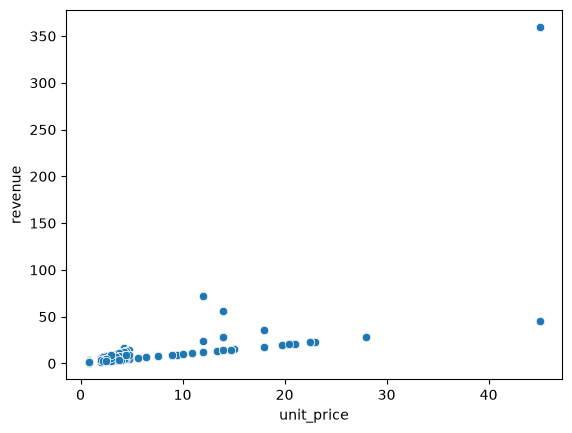

In [69]:
sns.scatterplot(data=df, x="unit_price", y="revenue")
plt.show()


## Business Insight
Customers usually buy one or two items per transaction. Higher-priced products are linked to slightly smaller quantities, but the relationship is weak.

## Conclusion
The coffee category generated the most revenue, and Hell’s Kitchen had the highest sales among the three stores. Most customers bought one or two items: one item was the most common quantity, and about 98% of transactions were for one or two items.